# Process ATL08 in Boreal with 30m rebinning via Sliderule 

Early versions of the ICESat-2 ATL08 processing workflow steps:
1. convert ATL08 100 m granules into ATL08 30 m granules
2. clip to tiles, filter, and convert the ATL08 30 m from .h5 granules to .csvs

This version aims to do all of those steps to simplify the process.  This notebook will show:
1. Select a particular tile
2. Use Sliderule to:  
 pull out all of the measurements over a specific tile  
 arrange them into 30m along-track segments using the `above_classifier`  
3. Filter the ATL08 geodataframe returning geoparquet files for each tile

## Import libaries

#### Install from source to match version on server
```bash
git clone https://github.com/SlideRuleEarth/sliderule.git  
cd sliderule/clients/python
pip install .
```

`Depreacated:` Importing sliderule.  This is installed onto the workspace with a conda call such as:
 
`conda install -c conda-forge sliderule`  
`pip install sliderule`

After the package is installed in the workspace, it can be imported as normal

In [1]:
#!conda update -c conda-forge sliderule

In [2]:
pip install sliderule --upgrade

  Attempting uninstall: sliderule
    Found existing installation: sliderule 4.8.6
    Uninstalling sliderule-4.8.6:
      Successfully uninstalled sliderule-4.8.6
Note: you may need to restart the kernel to use updated packages.


In [3]:
#!eval /projects/my-private-bucket/sliderule_clone_git.txt

In [4]:
pip install cogeo_mosaic==8.2.0

  Using cached cogeo_mosaic-8.2.0-py3-none-any.whl.metadata (19 kB)
  Using cached pydantic_settings-2.14.1-py3-none-any.whl.metadata (3.4 kB)
  Using cached supermorecado-0.2.0-py3-none-any.whl.metadata (9.2 kB)
  Using cached typing_inspection-0.4.2-py3-none-any.whl.metadata (2.6 kB)
Using cached cogeo_mosaic-8.2.0-py3-none-any.whl (40 kB)
Using cached pydantic_settings-2.14.1-py3-none-any.whl (60 kB)
Using cached supermorecado-0.2.0-py3-none-any.whl (15 kB)
Using cached typing_inspection-0.4.2-py3-none-any.whl (14 kB)
Note: you may need to restart the kernel to use updated packages.


In [5]:
pip install contextily

  Using cached contextily-1.7.0-py3-none-any.whl.metadata (3.1 kB)
Using cached contextily-1.7.0-py3-none-any.whl (16 kB)
Note: you may need to restart the kernel to use updated packages.


In [6]:
import matplotlib.pyplot as plt
import matplotlib
import geopandas as gpd
import logging 
import sliderule
from sliderule import icesat2

In [7]:
sliderule.__version__

'5.4.3'

In [8]:
sliderule.__version__

'5.4.3'

In [9]:
sliderule.init()

True

In [10]:
ICESAT2_BOREAL_REPO_PATH = '/projects/code/icesat2_boreal'               #'/projects/icesat2_boreal' # /projects/Developer/icesat2_boreal/lib
ICESAT2_BOREAL_LIB_PATH = ICESAT2_BOREAL_REPO_PATH + '/lib'
import sys, os
sys.path.append(ICESAT2_BOREAL_LIB_PATH)
import CovariateUtils
import maplib_folium
import mosaiclib
from mosaiclib import *
from pathlib import Path
import glob
import contextily as ctx

## Part 1: Read Boreal Tile Geopackage w/ locations of tiles

Tiles define the polygon extents used in the spatial selection of ATL03/08

In [11]:
# Boreal Tiles 
boreal_tiles_model_ready_fn = '/projects/shared-buckets/montesano/databank/boreal_tiles_v004_model_ready.gpkg'
boreal_tiles = gpd.read_file(boreal_tiles_model_ready_fn)

In [12]:
len(boreal_tiles)
#boreal_tiles.explore()

4956

## Part 2: Collect ATL08 by tile via Sliderule

Next part uses Sliderule to find ATL08 measurements within a tile.  Sliderule will also re-aggregate ATL08 data from 100 m alongtrack measurements to 30 m alongtrack measurements using `PhoReal`.  The result will put the results in a `geopandas` dataframe.


### Initialize Sliderule Client
- For public use, the default organization's node is `sliderule`;  
- For non-public use and testing, the `utexas` node can be used.  
     + a `.netrc` file will need to be configured.
- Number of nodes will increase speed, for now we will just use '1'
- More info on initializing is given here: https://slideruleearth.io/web/rtd/api_reference/icesat2.html#init

`NOTE`: (Feb 2024)   
using public branch of SlideRule  
    + the latest bug fix isnt on this public branch  
    + better to run on `utexas` node - but need to figure out permissions issue when run from ADE  
    
flag bug will still be here (2/22/2024) 
+ any flag that uses integers
+ indexing bug - so flag get incorrectly associated to the observations

### Processing parameters

For the sliderule query, we need to establish search parameters, these include:
 - Our geographic AOI (the tile extent)
 - t0 and t1 time start and time stop to query.  For testing we are just doing 1 year's worth of data
 - SRT (surface type) is defaulted to land, this is a required paramter but is not important for ATL08 sliderule
 - 'len' is the length of each extent in meters - this should be our bin size
 - 'res'  step distance for successive extents in meters - this needs to be the same as len for our purposes
 - 'pass_invalid' flag indicating whether or not extents that fail validation checks are still used and returned in the results - set 'True'
 - 'atl08_class' is set to ground, canopy, and top of canopy
 - 'atl08_fields' should be set to all fields of interest, in our case fields that we want to later apply filtering
 
 As for fields required, for the current iteration of filtering, `['h_can', 'h_can_unc','h_dif_ref','m','msw_flg','beam_type','seg_snow', 'sig_topo','seg_cover','sol_el','seg_landcov']` are used.  There are a few differences in PhoREAL naming conventions and Sliderule.  PhoREAL naming conventions were created to fit better into other functionality of PhoREAL while SlideRule fields are pulled directly from ATL08 (for the most part).  Here are how these map:
 
```
PhoREAL     : Sliderule
h_can       : h_canopy #(default field, doesn't need to be listed)
h_can_unc   : canopy/h_canopy_uncertainty #(field is in the 'canopy' subfield)
h_dif_ref   : h_dif_ref
m           : time #(month needs to be unpacked)
msw_flag    : msw_flag
beam_type   : spot #(will need to be converted to 'weak' and 'strong')
seg_snow    : snowcover #(default field)
sig_topo    : sigma_topo
seg_cover   : canopy/segment_cover #(field is in the 'canopy' subfield)
sol_el      : solar_elevation
seg_landcov : segment_landcover
rh25        : canopy_h_metrics[3]
rh50        : canopy_h_metrics[8]
rh60        : canopy_h_metrics[10]
rh70        : canopy_h_metrics[12]
rh75        : canopy_h_metrics[13]
rh80        : canopy_h_metrics[14]
rh85        : canopy_h_metrics[15]
rh90        : canopy_h_metrics[16]
rh95        : canopy_h_metrics[17]
```

Also the relative height metrics stored in PhoREAL as `rh25, rh50, rh60` etc. are stored in the `canopy_h_metrics`.  `canopy_h_metrics` store the percentile metrics as shown:
```
0 ,  1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13, 14, 15, 16, 17
10, 15, 20, 25, 30, 35, 40, 45, 50, 55, 60, 65, 70, 75, 80, 85, 90, 95
```

 First we will convert the extent to a polygon object

## Process ATL08 boreal
We custom process ATL08 for our boreal map. This involves:  
1. wrapping SlideRule and locking most SlideRule parameters
2. returning a geodataframe from SlideRule within the function
3. applying downstream custom ATL08 quality filtering on this geodataframe
4. writing a geoparquet of the final set of filtered ATL08; writing a companion metadata CSV  

In [13]:
from multiprocessing import Pool
from functools import partial

In [14]:
import multiprocessing as mp
n_cpu = mp.cpu_count() - 1
n_cpu

31

### Build a list of missing tiles

In [15]:
YEAR_ATL08 = 2025

In [16]:
import s3fs

In [17]:
s3 = s3fs.S3FileSystem(anon=False)

In [18]:
def get_missing_boreal_tiles_atl08(boreal_tiles, GLOB_STR=f'/projects/my-private-bucket/data/process_atl08_boreal/030m/{YEAR_ATL08}/*.parquet'):
    missing_tile_list = []
    f_list = glob.glob(GLOB_STR)
    # This glob wasnt updating???
    #f_list = s3.glob('s3://maap-ops-workspace/montesano/data/process_atl08_boreal/030m/2020/*.parquet')
    completed_tile_list = [int(f.split('_')[-1].split('.')[0]) for f in f_list]
    print(f'Completed tiles: {len(completed_tile_list)}')
    missing_tile_list = boreal_tiles[~boreal_tiles.tile_num.isin(completed_tile_list)].tile_num.to_list()
    print(f'Missing tiles: {len(missing_tile_list)}')
    return missing_tile_list

### Target set (requested)

In [87]:
atl08_compare_tiles = mosaiclib.set_seward + mosaiclib.set_brooks + mosaiclib.set_ak_interior + mosaiclib.set_c_ca + mosaiclib.set_n_queb + mosaiclib.set_bc_coast + \
mosaiclib.set_s_scand + mosaiclib.set_e_sib

In [88]:
boreal_tiles.tile_group.unique()

array(['eurasia west', 'north america east', 'eurasia central',
       'north america centra', 'north america west', 'eurasia east',
       'europe north', 'uk', 'fennoscand south', 'canada extra',
       'eurasia north', 'conus extra', 'alaska extra'], dtype=object)

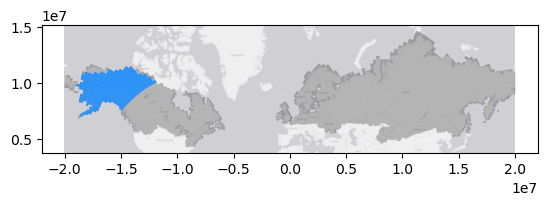

In [66]:
ax = boreal_tiles[boreal_tiles.tile_num.isin(boreal_tiles[boreal_tiles.tile_group == 'north america west'].tile_num.to_list())].to_crs(3857).plot(color='dodgerblue', ax=boreal_tiles.to_crs(3857).plot(color='black', alpha=0.25))
ctx.add_basemap(ax=ax, source=ctx.providers.Esri.WorldGrayCanvas, zoom=3, crs=3857, attribution=' ')

#### Have

In [15]:
ax = boreal_tiles[boreal_tiles.tile_num.isin(DICT_HAVE_TILES[2020])].to_crs(3857).plot(color='green', ax=boreal_tiles.to_crs(3857).plot(color='black', alpha=0.25))
ctx.add_basemap(ax=ax, source=ctx.providers.Esri.WorldGrayCanvas, zoom=3, crs=3857, attribution=' ')

NameError: name 'DICT_HAVE_TILES' is not defined

#### Need

In [16]:
ax = boreal_tiles[boreal_tiles.tile_num.isin(DICT_MISSING_TILES[2020])].to_crs(3857).plot(color='red', ax=boreal_tiles.to_crs(3857).plot(color='black', alpha=0.25))
ctx.add_basemap(ax=ax, source=ctx.providers.Esri.WorldGrayCanvas, zoom=3, crs=3857, attribution=' ')

NameError: name 'DICT_MISSING_TILES' is not defined

In [17]:
boreal_select = boreal_tiles[boreal_tiles.tile_num.isin(get_missing_boreal_tiles_atl08(boreal_tiles))]

# m = boreal_tiles.explore(color='black')
# boreal_select.explore(m=m, color='red')

Completed tiles: 0
Missing tiles: 4956


## Initialize server to process ATL08 with SlidRule

In [19]:
import process_atl08_boreal
import time

NASA MAAP


In [20]:
import importlib
importlib.reload(process_atl08_boreal)

<module 'process_atl08_boreal' from '/projects/code/icesat2_boreal/lib/process_atl08_boreal.py'>

In [21]:
def sliderule_init(PUBLIC=False):
    logging.basicConfig(level=logging.INFO)
    if PUBLIC:
        sliderule.init("slideruleearth.io", verbose=True, loglevel=logging.INFO, 
                     organization='sliderule', #'utexas'
                     desired_nodes=5)
    else:
        # # This version has the update that fixes an insidious flag bug (2/22/2024)
        # sliderule.init("slideruleearth.io", verbose=True, loglevel=logging.INFO, 
        #              organization='utexas', 
        #              desired_nodes=5, time_to_live=720)
        
        sliderule.init(desired_nodes=5, time_to_live=60, 
               user_service=True, # opens a web browser and prompts to login to GitHub
               verbose=True)

## Authenticate your GitHub account for use with SlideRule

In [24]:
sliderule_init(PUBLIC=False)

Invalid or expired token: 2026-05-29 15:02:38
INFO:sliderule.session:Invalid or expired token: 2026-05-29 15:02:38



GitHub Authentication Required

Please visit: https://github.com/login/device

And enter this code: 21C5-8050

Attempting to open browser... success.
Waiting for authorization... -

Login status to https://login.slideruleearth.io: success
INFO:sliderule.session:Login status to https://login.slideruleearth.io: success
Request not signed: [Errno 2] No such file or directory: '/projects/.sliderule_key'


success


Requesting deployment of sliderule: succeeded
INFO:sliderule.session:Requesting deployment of sliderule: succeeded
Waiting while cluster scales to desired capacity (currently at 0 nodes, desired is 5 nodes)... 2 seconds
INFO:sliderule.session:Waiting while cluster scales to desired capacity (currently at 0 nodes, desired is 5 nodes)... 2 seconds
Waiting while cluster scales to desired capacity (currently at 0 nodes, desired is 5 nodes)... 12 seconds
INFO:sliderule.session:Waiting while cluster scales to desired capacity (currently at 0 nodes, desired is 5 nodes)... 12 seconds
Waiting while cluster scales to desired capacity (currently at 0 nodes, desired is 5 nodes)... 22 seconds
INFO:sliderule.session:Waiting while cluster scales to desired capacity (currently at 0 nodes, desired is 5 nodes)... 22 seconds
Waiting while cluster scales to desired capacity (currently at 0 nodes, desired is 5 nodes)... 32 seconds
INFO:sliderule.session:Waiting while cluster scales to desired capacity (cur

# Example / Testing chunks

### Examine antimeridian (aka dateline) lon value issue

Dateline tile issue: 179 or -179 with .99999 (5 decimal places) will return 0 obs - but .9999 (4 decimal places) works  
Need to truncate dateline lons to 4 decimal places

In [95]:
region = sliderule.toregion(boreal_tiles[boreal_tiles.tile_num == 3638].to_crs(4326), cellsize=0.02)
region['poly']

[{'lon': -164.29320231386376, 'lat': 64.84902812660454},
 {'lon': -163.83496294529945, 'lat': 65.62353946868593},
 {'lon': -165.7687890462486, 'lat': 65.80241344492612},
 {'lon': -166.1756276008608, 'lat': 65.02272232340817},
 {'lon': -164.29320231386376, 'lat': 64.84902812660454}]

In [96]:
t0_year=2025 
t1_year=2025 
minmonth=6 
maxmonth=9
seg_length = 30
maxday = 30

params_atl08 = {
        # "poly": [{'lat': 67.2030717135289, 'lon': 179.999}, 
        #          {'lat': 66.40422871891515, 'lon': 179.999}, 
        #          {'lat': 66.39431431980967, 'lon': 178.15683833158522}, 
        #          {'lat': 67.19283094209065, 'lon': 178.09924555388685}],
        # "poly": [{'lat': 67.20295965989025, 'lon': -179.80114256174957}, 
        #          {'lat': 66.40412023797514, 'lon': -179.80717097235674}, 
        #          {'lat': 66.40422871891515, 'lon': -179.99999}, 
        #          {'lat': 67.2030717135289, 'lon': -179.99999}],
        "poly": region['poly'],
        "t0": f'{t0_year}-{minmonth:02}-01T00:00:00Z',
        "t1": f'{t1_year}-{maxmonth:02}-{maxday}T00:00:00Z',
        "srt": icesat2.SRT_LAND,
        "len": seg_length,
        "res": seg_length,
        "pass_invalid": True, 
        "atl08_class": ["atl08_ground", "atl08_canopy", "atl08_top_of_canopy"],
        "atl08_fields": ["canopy/h_canopy_uncertainty","h_dif_ref","msw_flag","sigma_topo","segment_landcover","canopy/segment_cover","segment_snowcover","terrain/h_te_uncertainty"],
    #'segment_cover' and 'h_canopy_uncertainty' need to be added
        #"atl08_fields": ["h_dif_ref","msw_flag","sigma_topo","segment_landcover"],
        "phoreal": {"binsize": 1.0, "geoloc": "center", "above_classifier": True, "use_abs_h": False, "send_waveform": False}
    }

In [97]:
params_atl08

{'poly': [{'lon': -164.29320231386376, 'lat': 64.84902812660454},
  {'lon': -163.83496294529945, 'lat': 65.62353946868593},
  {'lon': -165.7687890462486, 'lat': 65.80241344492612},
  {'lon': -166.1756276008608, 'lat': 65.02272232340817},
  {'lon': -164.29320231386376, 'lat': 64.84902812660454}],
 't0': '2025-06-01T00:00:00Z',
 't1': '2025-09-30T00:00:00Z',
 'srt': 0,
 'len': 30,
 'res': 30,
 'pass_invalid': True,
 'atl08_class': ['atl08_ground', 'atl08_canopy', 'atl08_top_of_canopy'],
 'atl08_fields': ['canopy/h_canopy_uncertainty',
  'h_dif_ref',
  'msw_flag',
  'sigma_topo',
  'segment_landcover',
  'canopy/segment_cover',
  'segment_snowcover',
  'terrain/h_te_uncertainty'],
 'phoreal': {'binsize': 1.0,
  'geoloc': 'center',
  'above_classifier': True,
  'use_abs_h': False,
  'send_waveform': False}}

In [98]:
import math

def truncate(number, digits) -> float:
    # Improve accuracy with floating point operations, to avoid truncate(16.4, 2) = 16.39 or truncate(-1.13, 2) = -1.12
    nbDecimals = len(str(number).split('.')[1]) 
    if nbDecimals <= digits:
        return number
    stepper = 10.0 ** digits
    return math.trunc(stepper * number) / stepper

In [99]:
for i,point in enumerate(params_atl08['poly']):
    print(f"Orig: {point['lon']}")
    if abs(point['lon']) > 179.9999:
        params_atl08['poly'][i]['lon'] = truncate(point['lon'], 4)
        print(f"\tTruncated: {params_atl08['poly'][i]['lon']}")

Orig: -164.29320231386376
Orig: -163.83496294529945
Orig: -165.7687890462486
Orig: -166.1756276008608
Orig: -164.29320231386376


In [45]:
#params_atl08["poly"] = params_atl03["poly"]

In [28]:
###############################
# Run SlideRule's implementation of PhoReal processing of ATL03 into custom ATL08
# https://slideruleearth.io/web/rtd/api_reference/icesat2.html#atl08p
atl08 = icesat2.atl08p(params_atl08, keep_id=True)

request <AppServer.8> retrieved 29 resources
INFO:sliderule.session:request <AppServer.8> retrieved 29 resources
Starting proxy for atl08 to process 29 resource(s) with 29 thread(s)
INFO:sliderule.session:Starting proxy for atl08 to process 29 resource(s) with 29 thread(s)
request <AppServer.10> processing initialized on ATL03_20250626052007_01602803_007_01.h5 ...
INFO:sliderule.session:request <AppServer.10> processing initialized on ATL03_20250626052007_01602803_007_01.h5 ...
request <AppServer.9> processing initialized on ATL03_20250904020648_12272803_007_01.h5 ...
INFO:sliderule.session:request <AppServer.9> processing initialized on ATL03_20250904020648_12272803_007_01.h5 ...
request <AppServer.8> processing initialized on ATL03_20250807155016_08082805_007_01.h5 ...
INFO:sliderule.session:request <AppServer.8> processing initialized on ATL03_20250807155016_08082805_007_01.h5 ...
request <AppServer.9> processing initialized on ATL03_20250811154159_08692805_007_01.h5 ...
INFO:slider

In [29]:
atl08.info()

<class 'geopandas.geodataframe.GeoDataFrame'>
DatetimeIndex: 118321 entries, 2025-06-01 06:37:24.201250304 to 2025-09-29 00:52:41.034864640
Data columns (total 29 columns):
 #   Column                       Non-Null Count   Dtype   
---  ------                       --------------   -----   
 0   extent_id                    118321 non-null  uint64  
 1   h_mean_canopy                95905 non-null   float32 
 2   ph_count                     118321 non-null  uint32  
 3   rgt                          118321 non-null  uint16  
 4   h_te_median                  118321 non-null  float32 
 5   h_min_canopy                 118321 non-null  float32 
 6   h_max_canopy                 118321 non-null  float32 
 7   veg_ph_count                 118321 non-null  uint32  
 8   landcover                    118321 non-null  uint8   
 9   canopy_openness              95905 non-null   float32 
 10  gt                           118321 non-null  uint8   
 11  spot                         118321 non-nu

In [49]:
#atl08_uav_05 = gpd.clip(atl08.reset_index().drop('time', axis=1), foot_uav.iloc[[5]])

In [50]:
#atl08_uav_05.explore(m=m_atl03, marker_type="circle", color='red', column='h_canopy')

In [30]:
import importlib
import FilterUtils

In [31]:
importlib.reload(FilterUtils)

<module 'FilterUtils' from '/projects/code/icesat2_boreal/lib/FilterUtils.py'>

In [63]:
# # Test filtering - wont work b/c 'month' field needs to be 'm' - this is handled in process_atl08_boreal() before this filtering is called.
# atl08, atl08_meta = FilterUtils.filter_atl08_qual_v5(atl08, atl08_cols_list = ['rh25','rh50','rh60','rh70','rh75','rh80','rh90','h_can','h_max_can', 'ter_slp','h_te_best', 'seg_landcov','sol_el','y','m','doy'], RETURN_METADATA=True)

### Test custom SlideRule wrapper for boreal ATL08 processing

In [54]:
importlib.reload(process_atl08_boreal)

<module 'process_atl08_boreal' from '/projects/code/icesat2_boreal/lib/process_atl08_boreal.py'>

In [65]:
mosaiclib.set_seward

[3637, 3638, 3639, 3543, 3544, 3545, 3731, 3732, 3733]

In [81]:
TEST_TILE_NUM = mosaiclib.set_seward[1] #3456 #3457 #354000

In [ ]:
sliderule_init(PUBLIC=False)
RES = 30
YEAR = 2025
OUTDIR = os.path.join('/projects/my-private-bucket/data/process_atl08_boreal',f'{RES:03}m', f'{YEAR}_test')
at08 = process_atl08_boreal.process_atl08_boreal(TEST_TILE_NUM, polygon_gdf_fn=boreal_tiles_model_ready_fn, id_col_num = 'tile_num', 
                                                 t0_year=YEAR, t1_year=YEAR, minmonth=1, maxmonth=9, seg_length=RES, 
                                                 outdir=OUTDIR, RETURN_DF=True, DEBUG=False, VERSION_ATL08=7)

# Apply multiprocessing of custom SlideRule wrapper for large batches
stagger multiprocessing, re-initialize server, handle server exceptions, assess missing tiles, continue the cycle until no more missing tiles  

### May 27 2025
+ the v6 data should be moved to `process_atl08_boreal/030m/v006/<YEAR>`
+ new v7 shoud go do `process_atl08_boreal/030m/v007/<YEAR>`

In [23]:
# Test get_missing_boreal_tiles_atl08()
RES = 30
YEAR = '2023'
VERSION_ATL08 = 7
#OUTDIR = os.path.join('/projects/my-private-bucket/data/process_atl08_boreal',f'{RES:03}m', f'{YEAR}_test') # <---------- TEST DIR
OUTDIR = os.path.join('/projects/my-private-bucket/data/process_atl08_boreal',f'{RES:03}m', f'v{VERSION_ATL08:03}', f'{YEAR}')
print(OUTDIR)
missing_tile_list = get_missing_boreal_tiles_atl08(boreal_tiles, GLOB_STR=f'{OUTDIR}/atl08_007_*.parquet') # v7 for all boreal tiles
#missing_tile_list = get_missing_boreal_tiles_atl08(boreal_tiles[boreal_tiles.tile_group == 'north america west'], GLOB_STR=f'{OUTDIR}/atl08_007_*.parquet') #v7 for atl08 compare tiles

/projects/my-private-bucket/data/process_atl08_boreal/030m/v007/2023
Completed tiles: 3112
Missing tiles: 1844


### Run this each October/November to get most recent June-Sept ATL08

In [32]:
sliderule_init(PUBLIC=False)

## Loop over multiprocessing subsets of N and wait T seconds
# Loop over N and wait
N = 10
T = 5

RES = 30
YEAR = '2019'
VERSION_ATL08 = 7
OUTDIR = os.path.join('/projects/my-private-bucket/data/process_atl08_boreal',f'{RES:03}m', f'v{VERSION_ATL08:03}', f'{YEAR}') # < --- new dir structure for v007
#OUTDIR = os.path.join('/projects/my-private-bucket/data/process_atl08_boreal',f'{RES:03}m', f'{YEAR}_test') # <---------- TEST DIR
!mkdir -p $OUTDIR
    
# missing_tile_list = get_missing_boreal_tiles_atl08(boreal_tiles, GLOB_STR=f'{OUTDIR}/*.parquet')#[0:10] # <------ TESTING !!!!
#missing_tile_list = get_missing_boreal_tiles_atl08(boreal_tiles[boreal_tiles.tile_num.isin(atl08_compare_tiles)], GLOB_STR=f'{OUTDIR}/atl08_007_*.parquet') 
#missing_tile_list = get_missing_boreal_tiles_atl08(boreal_tiles[boreal_tiles.tile_group == 'north america west'], GLOB_STR=f'{OUTDIR}/atl08_007_*.parquet') #v7 for atl08 compare tiles
missing_tile_list = get_missing_boreal_tiles_atl08(boreal_tiles, GLOB_STR=f'{OUTDIR}/atl08_007_*.parquet') # v7 for all boreal tiles

while len(missing_tile_list) > 0:
    
    # missing_tile_list = get_missing_boreal_tiles_atl08(boreal_tiles, GLOB_STR=f'{OUTDIR}/*.parquet')#[0:10] # <------ TESTING !!!!
    #missing_tile_list = get_missing_boreal_tiles_atl08(boreal_tiles[boreal_tiles.tile_num.isin(atl08_compare_tiles)], GLOB_STR=f'{OUTDIR}/atl08_007_*.parquet') 
    #missing_tile_list = get_missing_boreal_tiles_atl08(boreal_tiles[boreal_tiles.tile_group == 'north america west'], GLOB_STR=f'{OUTDIR}/atl08_007_*.parquet') #v7 for atl08 compare tiles
    missing_tile_list = get_missing_boreal_tiles_atl08(boreal_tiles, GLOB_STR=f'{OUTDIR}/atl08_007_*.parquet') # v7 for all boreal tiles
    
    ######
    # Multiprocessing 'process_atl08_boreal()' : SlideRule requests and Custom Filtering
    #####
    
    try:
        with Pool(processes=N) as pool:
            pool.map(partial(process_atl08_boreal.process_atl08_boreal, polygon_gdf_fn=boreal_tiles_model_ready_fn, id_col_num = 'tile_num', 
                             t0_year=YEAR, t1_year=YEAR, minmonth=6, maxmonth=9, seg_length = RES, VERSION_ATL08=VERSION_ATL08,
                             outdir=OUTDIR, 
                             RETURN_DF=False), 
                                    #boreal_tiles.tile_num.to_list() # All 4956 tiles
                                     missing_tile_list # Manually stagger runs over list
                                     )
    except:
        print('\nServer died? try again...')
        print(f'Wait for {T*2} seconds, then re-initialize server...\n')
        time.sleep(T*2)
        sliderule_init()
        
    print(f'\n\n\n---------Wait for {T} seconds...----------\n\n\n')
    time.sleep(T)

Invalid or expired token: 2026-06-09 11:18:47
INFO:sliderule.session:Invalid or expired token: 2026-06-09 11:18:47



GitHub Authentication Required

Please visit: https://github.com/login/device

And enter this code: E6A7-F9E4

Attempting to open browser... success.
Waiting for authorization... -

Login status to https://login.slideruleearth.io: success
INFO:sliderule.session:Login status to https://login.slideruleearth.io: success
Request not signed: [Errno 2] No such file or directory: '/projects/.sliderule_key'


success


Requesting deployment of sliderule: succeeded
INFO:sliderule.session:Requesting deployment of sliderule: succeeded
Waiting while cluster scales to desired capacity (currently at 0 nodes, desired is 5 nodes)... 3 seconds
INFO:sliderule.session:Waiting while cluster scales to desired capacity (currently at 0 nodes, desired is 5 nodes)... 3 seconds
Waiting while cluster scales to desired capacity (currently at 0 nodes, desired is 5 nodes)... 13 seconds
INFO:sliderule.session:Waiting while cluster scales to desired capacity (currently at 0 nodes, desired is 5 nodes)... 13 seconds
Waiting while cluster scales to desired capacity (currently at 0 nodes, desired is 5 nodes)... 23 seconds
INFO:sliderule.session:Waiting while cluster scales to desired capacity (currently at 0 nodes, desired is 5 nodes)... 23 seconds
Waiting while cluster scales to desired capacity (currently at 0 nodes, desired is 5 nodes)... 33 seconds
INFO:sliderule.session:Waiting while cluster scales to desired capacity (cur

...

Invalid or expired token: 2026-06-11 08:00:40
INFO:sliderule.session:Invalid or expired token: 2026-06-11 08:00:40



GitHub Authentication Required

Please visit: https://github.com/login/device

And enter this code: DA06-E084

Attempting to open browser... success.
Waiting for authorization... -

failed to authenticate to https://login.slideruleearth.io
ERROR:sliderule.session:failed to authenticate to https://login.slideruleearth.io
Failure attempting to authenticate: {'status': 'error'}
ERROR:sliderule.session:Failure attempting to authenticate: {'status': 'error'}
Login status to https://login.slideruleearth.io: failure
INFO:sliderule.session:Login status to https://login.slideruleearth.io: failure


failure


TypeError: 'NoneType' object is not subscriptable

### Basic multiprocessing

In [ ]:
# %%time

# ######
# # Multiprocessing 'process_atl08_boreal()' : SlideRule requests and Custom Filtering
# #####

# RES = 30
# YEAR = '2024'
# OUTDIR = os.path.join('/projects/my-private-bucket/data/process_atl08_boreal',f'{RES:03}m', YEAR)

# missing_tile_list = get_missing_boreal_tiles_atl08(boreal_tiles, GLOB_STR=f'{OUTDIR}/*.parquet')
# missing_tile_list = list(range(1322,1330))

# with Pool(processes=10) as pool:
#     pool.map(partial(process_atl08_boreal.process_atl08_boreal, polygon_gdf_fn=boreal_tiles_model_ready_fn, id_col_num = 'tile_num', t0_year=YEAR, t1_year=YEAR, minmonth=6, maxmonth=9, seg_length = RES, 
#                      outdir=OUTDIR, 
#                      RETURN_DF=False), 
#                               #boreal_tiles.tile_num.to_list()[0:31]
#                               #FOCAL_TILE_LIST[-2:] # Test selection of 31 tiles
#                               #boreal_tiles.tile_num.to_list() # All 4956 tiles
#                               missing_tile_list # Manually stagger runs over lists of 100
#                              )